# 03 · Cricket Ball Tracking

Find a cricket ball in video frames with OpenCV, follow it with a Kalman filter, and be honest about how well that worked.

Needs: numpy, matplotlib, opencv-python-headless (`pip install -r notebooks/requirements.txt`).

> Running in Google Colab? Run this once in a new cell first (replace the URL with wherever your copy of the project lives), then run the notebook from the top:
> ```python
> !git clone https://github.com/YOUR-ACCOUNT/pitchvision.git   # or upload and unzip the project folder
> %cd pitchvision
> !pip install -q -r notebooks/requirements.txt
> ```

> About the data. The CSV files in `notebooks/data/` are synthetic: generated by `pitchvision/sample_data.py` with a fixed random seed. The players, matches and numbers are invented so the notebook can run straight away. They are not a real team's results. To use your own data, replace the CSV files with files that have the same columns (see `notebooks/data/DATA_DICTIONARY.md`).

In [1]:
# --- Setup: find the project folder so the shared `pitchvision` package can be imported ---
import sys
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "pitchvision").exists():        # the notebook is being run from notebooks/
    ROOT = ROOT.parent
if not (ROOT / "pitchvision").exists():
    raise RuntimeError("Cannot find the 'pitchvision' folder. Open this notebook from inside the PitchVision "
                       "project, or see the Google Colab instructions in notebooks/README.md.")
sys.path.insert(0, str(ROOT))

DATA = ROOT / "notebooks" / "data"             # sample CSV files (SYNTHETIC data)
EXPORTS = ROOT / "notebooks" / "exports"       # CSV files written by the notebooks
EXPORTS.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 11})
INK, GREEN, RED, YELLOW = "#0D1310", "#1F6B45", "#B3261E", "#F2C230"
print("Project folder:", ROOT)

Project folder: /Users/sahasreddy/Documents/Cricket


## 1. Use your own video

Set `VIDEO_PATH` to a clip of one delivery filmed from a fixed camera. With `VIDEO_PATH = None` the notebook writes a synthetic clip (a red dot that flies, bounces and rises) for which the true ball position is known in every frame, so tracking error can be measured.

In [2]:
VIDEO_PATH = None        # e.g. "delivery.mp4"
BALL_COLOUR = "red"      # "red", "white", "pink" or None (motion only)

import cv2, os, tempfile
from pitchvision import tracking, trajectory

truth = None
path = VIDEO_PATH
if path is None:
    path = os.path.join(tempfile.mkdtemp(), "synthetic_ball.mp4")
    truth = tracking.write_synthetic_ball_video(path, noise=4.0, seed=3)
    print("Using a SYNTHETIC clip with known ball positions.")
cap, info = tracking.open_video(path); cap.release()
info

Using a SYNTHETIC clip with known ball positions.


{'fps': 120.0,
 'fps_assumed': False,
 'frame_count': 46,
 'width': 640,
 'height': 360,
 'duration_s': 0.38333333333333336}

## 2. Step by step on one frame

1. Background subtraction learns what the still scene looks like and marks pixels that changed.
2. Contours outline each moving blob.
3. Each blob is scored for roundness: circularity = 4π·area / perimeter² (1.0 for a perfect circle), and optionally for matching the ball's colour.

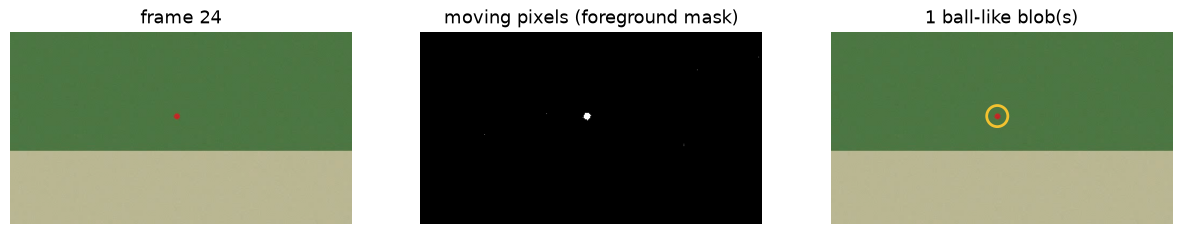

,x,y,r,score,circularity
0,311.5,157.5,7.91,1.02,0.8


In [3]:
bg = cv2.createBackgroundSubtractorMOG2(history=120, varThreshold=28, detectShadows=False)
frames = list(tracking.extract_frames(path, max_frames=80, resize_width=960))
masks = [bg.apply(img) for _, _, img in frames]
k = min(len(frames) - 1, 24)                                   # a frame part-way through the flight
idx, t, img = frames[k]
candidates = tracking.detect_candidates(img, masks[k], BALL_COLOUR)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
axes[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); axes[0].set_title(f"frame {idx}")
axes[1].imshow(masks[k], cmap="gray"); axes[1].set_title("moving pixels (foreground mask)")
axes[2].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); axes[2].set_title(f"{len(candidates)} ball-like blob(s)")
for c in candidates:
    axes[2].add_patch(plt.Circle((c["x"], c["y"]), max(c["r"] * 2.5, 8), fill=False, color=YELLOW, lw=2))
for ax in axes: ax.axis("off")
plt.show()
pd.DataFrame(candidates).round(2)

## 3. Linking detections with a Kalman filter

The filter keeps an estimate of the ball's position and velocity. Each frame it predicts where the ball should be, then corrects itself with the nearest detection. A detection far from the prediction is ignored. If the ball is not found, the filter coasts for up to four frames; those positions are marked `observed = False` so they are never mistaken for measurements.

In [4]:
result = tracking.track_ball(path, colour=BALL_COLOUR)
print("Status:", result["status"])
print("Observed points :", result["observed_count"])
print("Predicted points:", result["predicted_count"], "(filled in while the ball was not detected)")
print("Detection rate  :", round(result["detection_rate"] * 100), "%")
print("Confidence      :", result["confidence_label"], f"({result['confidence']:.2f})")
track = pd.DataFrame(result["points"])
track.head(8).round(2)

Status: ok
Observed points : 34
Predicted points: 0 (filled in while the ball was not detected)
Detection rate  : 100 %
Confidence      : high (0.99)


,frame,t,x,y,r,observed,confidence,sigma_px
0,8,0.07,40.23,60.23,8.16,True,1.00,5.00
1,9,0.08,56.77,60.77,8.16,True,1.00,2.82
2,10,0.08,73.50,63.50,7.91,True,1.00,2.72
3,11,0.09,91.50,67.50,7.91,True,1.00,2.62
4,12,0.10,107.86,71.14,8.01,True,1.00,2.58
5,13,0.11,125.50,75.50,7.91,True,1.00,2.57
6,14,0.12,141.93,80.29,8.72,True,0.94,2.56
7,15,0.12,158.77,86.23,8.16,True,0.99,2.56


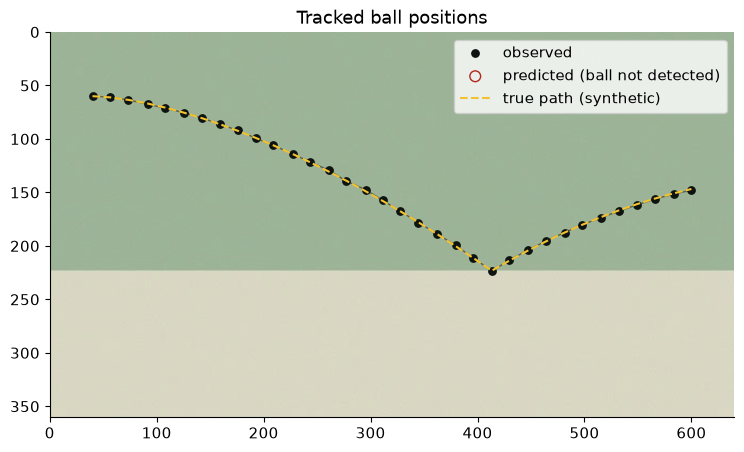

In [5]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.imshow(cv2.cvtColor(frames[0][2], cv2.COLOR_BGR2RGB), alpha=0.55,
          extent=[0, info["width"], info["height"], 0])
obs, pred = track[track["observed"]], track[~track["observed"]]
ax.plot(track["x"], track["y"], color=INK, lw=1, alpha=0.5)
ax.scatter(obs["x"], obs["y"], color=INK, s=28, label="observed")
ax.scatter(pred["x"], pred["y"], facecolors="none", edgecolors=RED, s=60, label="predicted (ball not detected)")
if truth:
    tr = pd.DataFrame(truth["truth"]); ax.plot(tr["x"], tr["y"], "--", color=YELLOW, lw=1.5, label="true path (synthetic)")
ax.set_title("Tracked ball positions"); ax.legend(); ax.grid(False); plt.show()

## 4. How accurate was it?

Only possible because the clip is synthetic and the true position is known.

In [6]:
if truth:
    tr = pd.DataFrame(truth["truth"]).set_index("frame")
    joined = obs.set_index("frame").join(tr, rsuffix="_true").dropna(subset=["x_true"])
    err = np.hypot(joined["x"] - joined["x_true"], joined["y"] - joined["y_true"])
    print(f"Mean error {err.mean():.2f} px, worst {err.max():.2f} px over {len(err)} observed points")
    print(f"Ball visible in {len(tr)} frames; detected in {len(joined)} ({len(joined) / len(tr) * 100:.0f}%)")
    bounce = trajectory.detect_bounce(result["points"])
    print("Bounce found at frame", bounce.get("frame"), "| true bounce frame", truth["bounce_frame"])
else:
    print("No ground truth for a real video: accuracy cannot be measured, only the confidence indicators above.")

Mean error 0.59 px, worst 1.33 px over 34 observed points
Ball visible in 34 frames; detected in 34 (100%)
Bounce found at frame 29 | true bounce frame 30


/var/folders/9t/b36q0b4n62v1k83dz5btqz8w0000gn/T/ipykernel_28191/1590460755.py:3: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  joined = obs.set_index("frame").join(tr, rsuffix="_true").dropna(subset=["x_true"])


## 5. What makes tracking fail

We add more and more camera noise to the synthetic clip and watch the detection rate. Real footage has worse problems (motion blur, a tiny ball, players in the way).

In [7]:
rows = []
for noise in [0, 4, 8, 14, 22]:
    p = os.path.join(tempfile.mkdtemp(), f"noise_{noise}.mp4")
    t_ = tracking.write_synthetic_ball_video(p, noise=noise, seed=5)
    r = tracking.track_ball(p, colour="red")
    rows.append({"noise": noise, "status": r["status"], "observed": r["observed_count"], "true_frames": len(t_["truth"]),
                 "confidence": round(r["confidence"], 2), "label": r["confidence_label"]})
noise_table = pd.DataFrame(rows); noise_table

,noise,status,observed,true_frames,confidence,label
0,0,ok,34,34,0.96,high
1,4,ok,34,34,0.98,high
2,8,ok,34,34,0.99,high
3,14,ok,34,34,0.99,high
4,22,ok,24,34,0.99,high


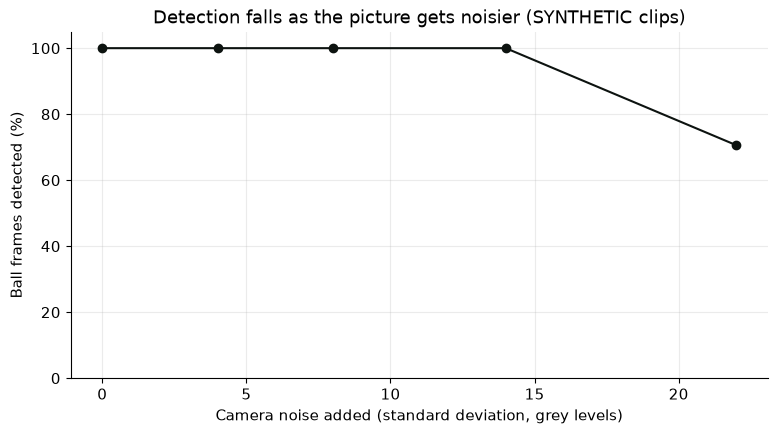

insufficient - Only 0 ball positions were detected; at least 6 are needed. Try a higher frame rate, a fixed camera, better light, or a ball colour that contrasts with the background.


In [8]:
fig, ax = plt.subplots()
ax.plot(noise_table["noise"], noise_table["observed"] / noise_table["true_frames"] * 100, marker="o", color=INK)
ax.set_xlabel("Camera noise added (standard deviation, grey levels)"); ax.set_ylabel("Ball frames detected (%)")
ax.set_ylim(0, 105); ax.set_title("Detection falls as the picture gets noisier (SYNTHETIC clips)"); plt.show()

# A clip with nothing moving gives 'insufficient', not an error and not an invented track.
still = os.path.join(tempfile.mkdtemp(), "still.mp4")
w = cv2.VideoWriter(still, cv2.VideoWriter_fourcc(*"mp4v"), 30, (320, 180))
for _ in range(20): w.write(np.full((180, 320, 3), 90, np.uint8))
w.release()
r = tracking.track_ball(still)
print(r["status"], "-", r["reason"])
track.to_csv(EXPORTS / "ball_track_example.csv", index=False)

## Summary

### Key findings
- Background subtraction plus a roundness test finds the ball in the synthetic clip; a Kalman filter links the detections.
- On the clean synthetic clip the mean position error is around a pixel and the bounce frame is found within a frame or two.
- Detection falls away as picture noise rises, and a clip with no moving ball returns 'insufficient'.

### Interpretation
Tracking quality depends far more on the footage than on the algorithm. A fixed camera, good light, a ball that contrasts with the background and a high frame rate (120-240 fps) matter most.

### Limitations
- At 30 fps a 100 km/h ball moves about 0.9 m between frames and smears into a streak.
- The ball is a few pixels wide in a wide shot and is hidden by the bowler and batter.
- Any small round moving object can be mistaken for the ball.
- Positions are pixels, not metres: one camera cannot measure depth.
- The accuracy figures here come from a synthetic clip with a clean, bright ball; real footage will be worse.

### How this notebook connects to the application
The Bowling Lab (Ball tracking, Swing and seam) and DRS Studio upload a clip to `POST /api/video/track`, which calls `pitchvision.tracking.track_ball` and returns the same observed/predicted points, detection rate and confidence shown here.